Differenze strutturali:
- Input: I modelli pre-trainati (ImageNet) di SegFormer si aspettano 3 canali (RGB), mentre tu hai 1 canale (Grayscale).
- Output: L'implementazione Hugging Face di SegFormer restituisce logits con risoluzione $\frac{H}{4} \times \frac{W}{4}$. Devi fare l'upsampling manuale per tornare a $512 \times 512$ e calcolare la loss.

# IMPORTS

In [ ]:
# Core
import os
import cv2
import io
import gc
import base64
import numpy as np
import pandas as pd
from pathlib import Path
from collections import defaultdict
from datetime import datetime
import shutil
import random

import warnings
warnings.filterwarnings('ignore')

# Torch
import torch
from torch.amp import autocast, GradScaler
from torch.utils.data import Dataset, DataLoader
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from torchvision import transforms, models

# monai
!pip install monai
import monai
from monai.networks.nets import UNet
from monai.networks.nets import AttentionUnet
from monai.losses import DiceCELoss, DiceFocalLoss, HausdorffDTLoss
from monai.metrics import DiceMetric, compute_hausdorff_distance, compute_dice
from monai.transforms import AsDiscrete
from monai.utils import MetricReduction

# transformer
!pip install transformers -q
from transformers import SegformerForSemanticSegmentation, SegformerConfig

# SKLearn
from sklearn.model_selection import StratifiedShuffleSplit, StratifiedKFold
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, accuracy_score

# Progress bar
from tqdm import tqdm

# Plotting
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Jupyter widgets
from IPython.display import HTML, display
import ipywidgets as widgets

In [2]:
!pip install ranger21 -q
from ranger21 import Ranger21

# LOADING DATASET

In [3]:
def load_patient_data(csv_path, images_dir):
    df = pd.read_excel(csv_path)
    patients_dict = defaultdict(list)
    
    for _, row in tqdm(df.iterrows(), total=len(df), desc="Caricamento dati"):
        img_name = row['US']
        mask_name = row['MASK']
        label = row['LABEL']

        img_stem = Path(img_name).stem
        parts = img_stem.split('_')
        patient_id = parts[0]

        img_path = str(Path(images_dir) / img_name)
        mask_path = str(Path(images_dir) / mask_name)

        pair = {
            'img_path': img_path,
            'mask_path': mask_path,
            'img_name': img_name,
            'label': label
        }

        patients_dict[patient_id].append(pair)
        
    patients = []
    
    for pid, samples in sorted(patients_dict.items(), key=lambda x: int(x[0])):
        labels = [s['label'] for s in samples]
        label_counts = np.bincount(labels)
        major_label = int(np.argmax(label_counts))

        patients.append(
            {
            'patient_id': pid,
            'samples': samples,
            'major_label': major_label
            }
        )

    return patients

## Kaggle Data Loading

In [4]:
INPUT_DIRECTORY = '/kaggle/input/breast-lesions/'
TRAINING_DIRECTORY = INPUT_DIRECTORY + 'train/'
IMG_DIRECTORY = TRAINING_DIRECTORY + 'images'
LABELS_DIRECTORY = TRAINING_DIRECTORY + 'train_metadata.xlsx'

train_data = load_patient_data(LABELS_DIRECTORY, IMG_DIRECTORY)
train_labels = pd.read_excel(LABELS_DIRECTORY)

print(f"\n✅ Loaded {len(train_data)} patients.")

Caricamento dati: 100%|██████████| 1195/1195 [00:00<00:00, 14018.83it/s]


✅ Loaded 774 patients.


# PRE-PROCESSING

## Cropping

In [8]:
def segmentation_crop(img, mask, output_size=512):

    h, w = img.shape


    coords = cv2.findNonZero(mask)
    if coords is None:

        center_x, center_y = w // 2, h // 2
    else:
        x, y, bw, bh = cv2.boundingRect(coords)
        center_x = x + bw // 2
        center_y = y + bh // 2


    crop_size = min(h, w)


    half = crop_size // 2
    x1 = center_x - half
    y1 = center_y - half
    x2 = center_x + half
    y2 = center_y + half


    if x1 < 0:
        x2 -= x1
        x1 = 0
    if y1 < 0:
        y2 -= y1
        y1 = 0
    if x2 > w:
        x1 -= (x2 - w)
        x2 = w
    if y2 > h:
        y1 -= (y2 - h)
        y2 = h


    x1, y1 = max(0, x1), max(0, y1)
    x2, y2 = min(w, x2), min(h, y2)


    crop_img = img[y1:y2, x1:x2]
    crop_mask = mask[y1:y2, x1:x2]


    final_img = cv2.resize(crop_img, (output_size, output_size), interpolation=cv2.INTER_CUBIC)
    final_mask = cv2.resize(crop_mask, (output_size, output_size), interpolation=cv2.INTER_NEAREST)

    return final_img, final_mask

## Inpainting

In [9]:
def has_colors(img,
            sat_thresh=40,
            delta_thresh=20,
            min_region_area=20,
            max_region_area_ratio=0.1,
            max_aspect_ratio=5,
            mean_delta_thresh=15,
            dilate_iters=1,
            erode_iters=1):



    b, g, r = cv2.split(img)
    r = r.astype(np.int16)
    g = g.astype(np.int16)
    b = b.astype(np.int16)

    delta = np.maximum.reduce([np.abs(r - g), np.abs(r - b), np.abs(g - b)])
    mask_rgb = delta > delta_thresh


    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mask_sat = hsv[:, :, 1] > sat_thresh


    mask = np.logical_and(mask_rgb, mask_sat).astype(np.uint8) * 255
    if np.sum(mask) == 0:
        return False, mask


    kernel_h = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 1))
    kernel_v = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 3))
    kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

    mask = cv2.dilate(mask, kernel_h, iterations=dilate_iters)
    mask = cv2.dilate(mask, kernel_v, iterations=dilate_iters)
    mask = cv2.morphologyEx(mask, cv2.MORPH_CLOSE, kernel_close)


    num_labels, labels, stats, _ = cv2.connectedComponentsWithStats(mask, connectivity=8)
    h, w = mask.shape
    img_area = h * w

    filtered = np.zeros_like(mask)
    rect = np.zeros_like(mask)
    detected = False

    for i in range(1, num_labels):
        area = stats[i, cv2.CC_STAT_AREA]
        x, y, width, height = stats[i, cv2.CC_STAT_LEFT], stats[i, cv2.CC_STAT_TOP], stats[i, cv2.CC_STAT_WIDTH], stats[i, cv2.CC_STAT_HEIGHT]
        aspect_ratio = max(width / (height + 1e-5), height / (width + 1e-5))


        region_mask = labels == i
        mean_delta = delta[region_mask].mean()
        std_delta = delta[region_mask].std()
        mean_sat = hsv[:, :, 1][region_mask].mean()
        std_sat = hsv[:, :, 1][region_mask].std()


        if (min_region_area < area < max_region_area_ratio * img_area):
            filtered[region_mask] = 255
            detected = True

        elif ((aspect_ratio > max_aspect_ratio) and
            (mean_delta > mean_delta_thresh) and std_delta < 1 and
            mean_sat > 25 and std_sat < 1):
            rect[region_mask] = 255
            detected = True


    kernel_h = cv2.getStructuringElement(cv2.MORPH_RECT, (200, 1))
    kernel_v = cv2.getStructuringElement(cv2.MORPH_RECT, (1, 200))
    kernel_close = cv2.getStructuringElement(cv2.MORPH_RECT, (3, 3))

    rect = cv2.dilate(rect, kernel_h, iterations=dilate_iters)
    rect = cv2.dilate(rect, kernel_v, iterations=dilate_iters)
    rect = cv2.morphologyEx(rect, cv2.MORPH_CLOSE, kernel_close)

    kernel_corner = cv2.getStructuringElement(cv2.MORPH_RECT, (10, 10))
    rect = cv2.morphologyEx(rect, cv2.MORPH_CLOSE, kernel_corner)

    if erode_iters > 0:
        rect = cv2.erode(rect, kernel_close, iterations=erode_iters)

    filtered = cv2.bitwise_or(filtered, rect)

    return detected, filtered

In [10]:
def remove_ink(img, ink_mask):


    mask = ink_mask


    img_inpainted = cv2.inpaint(img, mask, inpaintRadius=3, flags=cv2.INPAINT_TELEA)

    return img_inpainted

In [11]:
def inpaint(img):

    hasColors, color_mask = has_colors(img)

    if hasColors:
        img_clean = remove_ink(img, color_mask)
        return img_clean
    else:
        return img

## Noise Filter

In [12]:
# median filtering
def apply_median_filter(image, kernel_size=5):

    denoised = cv2.medianBlur(image.astype(np.uint8), kernel_size)
    return denoised

## Normalization

In [13]:
def apply_clahe(image, clip_limit=2.0, tile_grid_size=(8, 8)):

    clahe = cv2.createCLAHE(clipLimit=clip_limit, tileGridSize=tile_grid_size)
    return clahe.apply(image)

In [14]:
def apply_zscore_normalization(image):

    image = image.astype(np.float32)
    mean = np.mean(image)
    std = np.std(image)

    if std == 0:
        return image - mean

    return (image - mean) / std

# TRAIN-VAL SPLIT

Here, only B and M classes are maintained for the segmentation.

In [15]:
def load_segmentation_samples(patients):
    filtered_patients = []

    for patient in patients:
        filtered_samples = [s for s in patient['samples'] if s['label'] in [0, 1]]

        if len(filtered_samples) > 0:
            filtered_patients.append({
                'patient_id': patient['patient_id'],
                'samples': filtered_samples,
                'major_label': patient['major_label']
            })

    return filtered_patients

# K-FOLD CROSS VALIDATION

In [16]:
def stratified_kfold_split(patients, n_splits=3, random_state=42):

    major_labels = np.array([p['major_label'] for p in patients])

    skf = StratifiedKFold(n_splits=n_splits, shuffle=True, random_state=random_state)

    for train_idx, val_idx in skf.split(np.arange(len(patients)), major_labels):
        train_patients = [patients[i] for i in train_idx]
        val_patients = [patients[i] for i in val_idx]

        yield train_patients, val_patients

# SEGMENTATION TRAINING

## Configuration

In [17]:
class SegmentationConfig:
    # Training
    NUM_EPOCHS = 100
    BATCH_SIZE = 4
    LEARNING_RATE = 6e-5
    WEIGHT_DECAY = 1e-2

    # Data
    OUTPUT_SIZE = 512
    VAL_SPLIT = 0.2
    NUM_WORKERS = 2

    # Device
    DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

## Data Augmentation

In [18]:
class UltrasoundAugmentation:

    def __init__(self, p=0.7):
        self.p = p

    def __call__(self, img_tensor, mask_tensor=None):
        flip_h = random.random() < 0.5
        flip_v = random.random() < 0.5
        apply_random_affine = random.random() < self.p
    


        # Horizontal Flip
        if flip_h:
            img_tensor = torch.flip(img_tensor, dims=[2])
            if mask_tensor is not None:
                mask_tensor = torch.flip(mask_tensor, dims=[2])

        # Vertical Flip
        if flip_v:
            img_tensor = torch.flip(img_tensor, dims=[1])
            if mask_tensor is not None:
                mask_tensor = torch.flip(mask_tensor, dims=[1])

        # Random Affine: rotation + zoom/scale + shift (identica per entrambi)
        if apply_random_affine:
            # Parametri random
            angle = random.uniform(-15, 15)
            scale = random.uniform(0.8, 1.2) # Zoom tra 80% e 120%
            translate_x = random.uniform(-0.1, 0.1) * img_tensor.shape[2]
            translate_y = random.uniform(-0.1, 0.1) * img_tensor.shape[1]
            
            # Applica all'immagine e maschera
            img_tensor = transforms.functional.affine(
                img_tensor, 
                angle=angle, 
                translate=(translate_x, translate_y), 
                scale=scale, 
                shear=0
            )
            if mask_tensor is not None:
                mask_tensor = transforms.functional.affine(
                    mask_tensor, 
                    angle=angle, 
                    translate=(translate_x, translate_y), 
                    scale=scale, 
                    shear=0
                )


        # Brightness & Contrast vengono applicati SOLO all'immagine
        if random.random() < self.p:
            brightness_factor = random.uniform(0.8, 1.2)
            contrast_factor = random.uniform(0.8, 1.2)
            
            img_tensor = transforms.functional.adjust_brightness(
                img_tensor,
                brightness_factor
            )
            img_tensor = transforms.functional.adjust_contrast(
                img_tensor,
                contrast_factor
            )

        if mask_tensor is not None:
            return img_tensor, mask_tensor
        else:
            return img_tensor

## Dataset

In [19]:
class SegmentationDataset(Dataset):

    def __init__(self, samples, output_size=512, is_training=True):
        self.samples = samples
        self.output_size = output_size
        self.is_training = is_training

        self.augmentation = UltrasoundAugmentation(p=0.5) if is_training else None

    def __len__(self):
        return len(self.samples)

    def __getitem__(self, idx):
        sample = self.samples[idx]

        # Carica immagine e maschera
        img = cv2.imread(sample['img_path'], cv2.IMREAD_GRAYSCALE)
        mask = cv2.imread(sample['mask_path'], cv2.IMREAD_GRAYSCALE)

        # Crop centrato sulla lesione
        img, mask = segmentation_crop(img, mask, output_size=self.output_size)

        # Inpainting (rimuovi annotazioni colorate)
        img_rgb = cv2.cvtColor(img, cv2.COLOR_GRAY2RGB)
        img_rgb = inpaint(img_rgb)
        img = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

        # Noise filter
        img = apply_median_filter(img)

        # Normalization
        img = apply_clahe(img, clip_limit=3.0, tile_grid_size=(4,4))
        img = apply_zscore_normalization(img)


        img_tensor = torch.from_numpy(img).unsqueeze(0).float() 
        
        # Maschera (H, W) -> (1, H, W)
        mask = (mask > 127).astype(np.float32)
        mask_tensor = torch.from_numpy(mask).unsqueeze(0).float()


        if self.augmentation is not None:
            img_tensor, mask_tensor = self.augmentation(img_tensor, mask_tensor)
        # Output: Img (1, 512, 512), Mask (1, 512, 512)

        
        return img_tensor, mask_tensor

## Data Loaders

In [20]:
def create_seg_data_loaders(train_patients, val_patients, batch_size=32, num_workers=0):

    # --- FLATTENING: Da Lista Pazienti a Lista Samples ---
    train_samples = []
    for p in train_patients:
        train_samples.extend(p['samples'])
        
    val_samples = []
    for p in val_patients:
        val_samples.extend(p['samples'])


    train_dataset = SegmentationDataset(
        train_samples,
        is_training=True,
        output_size=SegmentationConfig.OUTPUT_SIZE
    )

    val_dataset = SegmentationDataset(
        val_samples,
        is_training=False,
        output_size=SegmentationConfig.OUTPUT_SIZE
    )

    # Crea dataloader
    train_loader = DataLoader(
        train_dataset,
        batch_size=batch_size,
        shuffle=True,
        num_workers=num_workers,
        pin_memory=False
    )

    val_loader = DataLoader(
        val_dataset,
        batch_size=batch_size,
        shuffle=False,
        num_workers=num_workers,
        pin_memory=False
    )

    return train_loader, val_loader

## Model

In [21]:
class SegFormerWrapper(nn.Module):

    def __init__(self, model_name="nvidia/mit-b0", num_classes=1):
        super().__init__()

        print(f"🔄 Loading SegFormer pretrained model: {model_name}...")
        


        self.segformer = SegformerForSemanticSegmentation.from_pretrained(
            model_name,
            num_labels=num_classes,
            ignore_mismatched_sizes=True
        )
        
    def forward(self, x):
        # x shape in ingresso: (Batch, 1, H, W) -> Grayscale
        
        # 1. Gestione Canali
        if x.shape[1] == 1:
            x = x.repeat(1, 3, 1, 1)

        # 2. Forward pass

        outputs = self.segformer(pixel_values=x)
        
        # 3. Upsampling
        logits = F.interpolate(
            outputs.logits,
            size=x.shape[-2:], 
            mode="bilinear",
            align_corners=False
        )
        return logits

## Loss Functions

In [23]:
class BoundaryAwareLoss(nn.Module):
    def __init__(self, mode="dice_ce", weight_main=1.0, weight_boundary=0.5, warmup_epochs=5):
        super().__init__()
        self.weight_main = weight_main
        self.target_boundary_weight = weight_boundary # Salviamo il peso target
        self.warmup_epochs = warmup_epochs
        
        # 1. Definizione della Loss Principale (Area)
        if mode == "dice_focal":
            self.main_loss = DiceFocalLoss(sigmoid=True, lambda_dice=1.0, lambda_focal=1.0, batch=True)
        else:
            self.main_loss = DiceCELoss(sigmoid=True, squared_pred=True, batch=True)
            
        # 2. Definizione della Loss sul Bordo (Contorno)
        self.boundary_loss = HausdorffDTLoss(sigmoid=True, batch=True)

    def forward(self, input_pred, target_mask, current_epoch=None):
        # Calcolo Loss Area (Dice/Focal)
        loss_area = self.main_loss(input_pred, target_mask)
        
        # Gestione Warm-up

        if current_epoch is not None and current_epoch < self.warmup_epochs:
            active_boundary_weight = 0.0
        else:
            active_boundary_weight = self.target_boundary_weight

        # Calcolo Loss Bordo
        loss_bound = torch.tensor(0.0, device=input_pred.device, requires_grad=True)
        
        if active_boundary_weight > 0:
            try:
                loss_bound = self.boundary_loss(input_pred, target_mask)
            except Exception:
                pass
            
        # Somma pesata
        total_loss = (self.weight_main * loss_area) + (active_boundary_weight * loss_bound)
        
        return total_loss

## Experiment Manager

In [24]:
class ExperimentManager:
    
    def __init__(self, base_dir="experiments", experiment_name=None):
        if experiment_name is None:
            timestamp = datetime.now().strftime("%Y%m%d_%H%M%S")
            experiment_name = f"seg_run_{timestamp}"
            
        self.save_dir = os.path.join(base_dir, experiment_name)
        self.weights_dir = os.path.join(self.save_dir, "weights")
        self.results_dir = os.path.join(self.save_dir, "results")
        self.samples_dir = os.path.join(self.save_dir, "samples") # Per visualizzazioni future
        
        os.makedirs(self.weights_dir, exist_ok=True)
        os.makedirs(self.results_dir, exist_ok=True)
        os.makedirs(self.samples_dir, exist_ok=True)
        
        self.fold_metrics = []
        print(f" I risultati verranno salvati in: {self.save_dir}")

    
    def save_fold_results(self, fold_idx, model, val_loader, device):
        print(f" Salvataggio risultati Fold {fold_idx}...")
        
        # 1. Salva i Pesi
        weight_path = os.path.join(self.weights_dir, f"model_fold{fold_idx}.pt")
        torch.save(model.state_dict(), weight_path)
        
        # 2. Calcolo Metriche Avanzate (Dice, HD95, Precision, Recall)
        model.eval()
        fold_dice = []
        fold_hd95 = []
        fold_precision = []
        fold_recall = []
        

        saved_samples = False 
        
        with torch.no_grad():
            for batch_idx, batch_data in enumerate(val_loader):

                if isinstance(batch_data, dict):
                    inputs, labels = batch_data["image"].to(device), batch_data["label"].to(device)
                else:
                    inputs, labels = batch_data[0].to(device), batch_data[1].to(device)


                outputs = model(inputs)
                preds = (torch.sigmoid(outputs) > 0.5).float()
                

                # Dice
                dice_score = compute_dice(y_pred=preds, y=labels, include_background=True)
                
                # Hausdorff (HD95)
                try:
                    hd95 = compute_hausdorff_distance(y_pred=preds, y=labels, include_background=True, percentile=95)
                except:
                    hd95 = torch.tensor([[np.nan]] * inputs.shape[0], device=device)

                # Precision & Recall
                tp = (preds * labels).sum(dim=(1, 2, 3))
                fp = (preds * (1 - labels)).sum(dim=(1, 2, 3))
                fn = ((1 - preds) * labels).sum(dim=(1, 2, 3))
                
                precision = tp / (tp + fp + 1e-6)
                recall = tp / (tp + fn + 1e-6)


                fold_dice.extend(dice_score.cpu().numpy().flatten())
                fold_hd95.extend(hd95.cpu().numpy().flatten())
                fold_precision.extend(precision.cpu().numpy().flatten())
                fold_recall.extend(recall.cpu().numpy().flatten())
                

                if not saved_samples:
                    np.save(os.path.join(self.samples_dir, f"fold{fold_idx}_inputs.npy"), inputs.cpu().numpy())
                    np.save(os.path.join(self.samples_dir, f"fold{fold_idx}_labels.npy"), labels.cpu().numpy())
                    np.save(os.path.join(self.samples_dir, f"fold{fold_idx}_preds.npy"), preds.cpu().numpy())
                    saved_samples = True


        df_fold = pd.DataFrame({
            'fold': fold_idx,
            'dice': fold_dice,
            'hd95': fold_hd95,
            'precision': fold_precision,
            'recall': fold_recall
        })
        

        df_fold.to_csv(os.path.join(self.results_dir, f"metrics_fold{fold_idx}.csv"), index=False)
        

        self.fold_metrics.append({
            'fold': fold_idx,
            'mean_dice': np.nanmean(fold_dice),
            'mean_hd95': np.nanmean(fold_hd95),
            'mean_precision': np.nanmean(fold_precision),
            'mean_recall': np.nanmean(fold_recall)
        })

    
    def save_final_summary(self):
        df = pd.DataFrame(self.fold_metrics)
        summary = df.describe().loc[['mean', 'std']]
        
        excel_path = os.path.join(self.save_dir, "final_segmentation_results.xlsx")
        with pd.ExcelWriter(excel_path) as writer:
            df.to_excel(writer, sheet_name='Folds Summary', index=False)
            summary.to_excel(writer, sheet_name='Statistics')
            
        print(f"✅ Report finale salvato in: {excel_path}")

## Post-Processing

In [25]:
def sharpen_mask(mask, threshold=0.5, morphology=True):
    # Assicuriamoci che sia uint8
    if mask.max() <= 1.0:
        mask = (mask * 255).astype(np.uint8)
    
    # Binarizza
    binary = (mask > (threshold * 255)).astype(np.uint8) * 255

    if morphology:
        # Kernel piccolo per preservare dettagli
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (3, 3))
        # Opening per rimuovere piccoli artefatti
        binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN, kernel, iterations=1)
        # Closing per chiudere piccoli buchi
        binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel, iterations=1)

    return binary




def refine_with_grabcut(image, coarse_mask, iterations=3):
    mask = np.zeros(image.shape[:2], dtype=np.uint8)


    mask[coarse_mask > 0.7] = cv2.GC_FGD
    mask[coarse_mask < 0.3] = cv2.GC_BGD
    mask[(coarse_mask >= 0.3) & (coarse_mask <= 0.7)] = cv2.GC_PR_FGD

    bgd_model = np.zeros((1, 65), dtype=np.float64)
    fgd_model = np.zeros((1, 65), dtype=np.float64)


    if len(image.shape) == 2:
        image = cv2.cvtColor(image, cv2.COLOR_GRAY2BGR)

    try:
        cv2.grabCut(image, mask, None, bgd_model, fgd_model, iterations, cv2.GC_INIT_WITH_MASK)

        refined = np.where((mask == cv2.GC_FGD) | (mask == cv2.GC_PR_FGD), 1, 0).astype(np.uint8)
        return refined
    
    except Exception as e:
        print(f" GrabCut fallito: {e}")
        return (coarse_mask > 0.5).astype(np.uint8)

## Training Functions

In [26]:
def visualize_predictions(model, val_loader, device, num_samples=4, use_grabcut=True):
    model.eval()
    

    batch = next(iter(val_loader))
    if isinstance(batch, dict):
        images, masks = batch["image"], batch["label"]
    else:
        images, masks = batch[0], batch[1]


    images = images[:num_samples].to(device)
    masks = masks[:num_samples]

    with torch.no_grad():
        preds = torch.sigmoid(model(images))


    num_cols = 4 if use_grabcut else 3
    fig, axes = plt.subplots(num_samples, num_cols, figsize=(4 * num_cols, 4 * num_samples))

    if num_samples == 1:
        axes = axes.reshape(1, -1)

    for i in range(min(num_samples, len(images))):
        # 1. Input Image
        img = images[i, 0].cpu().numpy()

        ax_row = axes[i] if num_samples > 1 else axes[0]
        
        ax_row[0].imshow(img, cmap='gray')
        ax_row[0].set_title('Input US')
        ax_row[0].axis('off')

        # 2. Ground Truth
        gt = masks[i, 0].cpu().numpy()
        ax_row[1].imshow(gt, cmap='gray')
        ax_row[1].set_title('Ground Truth')
        ax_row[1].axis('off')

        # 3. Predizione (Raw)
        pred_prob = preds[i, 0].cpu().numpy()
        ax_row[2].imshow(pred_prob, cmap='gray') # O 'jet' per vedere gradienti
        ax_row[2].set_title('Prediction (Raw)')
        ax_row[2].axis('off')

        # 4. Predizione con GrabCut + Sharpen
        if use_grabcut:

            img_uint8 = (img * 255).astype(np.uint8)
            

            refined_mask = refine_with_grabcut(img_uint8, pred_prob, iterations=5)
            

            final_mask = sharpen_mask(refined_mask, threshold=0.5, morphology=True)
            
            ax_row[3].imshow(final_mask, cmap='gray')
            ax_row[3].set_title('GrabCut + Sharpen')
            ax_row[3].axis('off')

    plt.tight_layout()
    plt.show()
    model.train()

In [27]:
def train_epoch_seg(model, loader, optimizer, criterion, scaler, device, epoch_idx):
    model.train()
    run_loss = 0.0


    accumulation_steps = 4
    optimizer.zero_grad()
    
    for i, batch_data in enumerate(loader):

        if isinstance(batch_data, dict):
            inputs, targets = batch_data["image"].to(device), batch_data["label"].to(device)
        else:
            inputs, targets = batch_data[0].to(device), batch_data[1].to(device)
        

        with torch.amp.autocast('cuda'): 
            logits = model(inputs)
            loss = criterion(logits, targets, current_epoch=epoch_idx)

            loss = loss / accumulation_steps
        

        scaler.scale(loss).backward()


        if (i + 1) % accumulation_steps == 0 or (i + 1) == len(loader):
            


            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

            scaler.step(optimizer)
            scaler.update()
            optimizer.zero_grad()


        run_loss += loss.item() * accumulation_steps
        
    return run_loss / len(loader)



def validate_seg(model, loader, criterion, device):
    model.eval()
    run_loss = 0.0
    run_dice = 0.0
    
    with torch.no_grad():
        for batch_data in loader:
            if isinstance(batch_data, dict):
                inputs, targets = batch_data["image"].to(device), batch_data["label"].to(device)
            else:
                inputs, targets = batch_data[0].to(device), batch_data[1].to(device)
            
            with torch.cuda.amp.autocast():
                logits = model(inputs)
                loss = criterion(logits, targets)
                logits = model(inputs)


                loss = criterion(logits, targets, current_epoch=100)
            
            run_loss += loss.item()
            

            preds = (torch.sigmoid(logits) > 0.5).float()
            dice_tensor = compute_dice(preds, targets, include_background=True)
            run_dice += dice_tensor.mean().item()
            
    return run_loss / len(loader), run_dice / len(loader)

## Training Loop

In [28]:
# --- CONFIGURAZIONE ---
n_splits = 2
num_epochs = SegmentationConfig.NUM_EPOCHS
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")



# 1. loading dei pazienti
all_patients = load_patient_data(LABELS_DIRECTORY, IMG_DIRECTORY)

# 2. Filtra i pazienti con label 0/1
seg_patients = load_segmentation_samples(all_patients)

# 3. Inizializza ExperimentManager
exp_manager = ExperimentManager(experiment_name="segFormer_mitb2")
fold_histories = []


# --- LOOP K-FOLD ---
for fold_num, (train_patients, val_patients) in enumerate(stratified_kfold_split(seg_patients, n_splits=n_splits)):


    gc.collect()
    torch.cuda.empty_cache()
    
    print(f"\n{'='*20} FOLD {fold_num + 1}/{n_splits} {'='*20}")
    print(f"Train patients: {len(train_patients)} | Val patients: {len(val_patients)}")
    
    # 1. Crea DataLoaders
    train_loader, val_loader = create_seg_data_loaders(
        train_patients, 
        val_patients, 
        batch_size=SegmentationConfig.BATCH_SIZE, 
        num_workers=SegmentationConfig.NUM_WORKERS
    )

    # 2. Reinizializza Modello
    model = SegFormerWrapper(
        model_name="nvidia/mit-b2",
        num_classes=1
    ).to(device)

    # 3. Optimizer
    optimizer = Ranger21(
        model.parameters(),
        lr=SegmentationConfig.LEARNING_RATE,
        weight_decay=SegmentationConfig.WEIGHT_DECAY,
        num_epochs=SegmentationConfig.NUM_EPOCHS,
        num_batches_per_epoch=len(train_loader),

        num_warmup_iterations=100 # Ranger21 gestisce il warmup internamente
    )
    
    # 3. Loss

    criterion = BoundaryAwareLoss(
        mode="dice_ce", 
        weight_main=1.0, 
        weight_boundary=0.0,
        warmup_epochs=5
    ).to(device)

    # 4. Scaler
    scaler = torch.cuda.amp.GradScaler() 

    # History
    history = {'train_loss': [], 'val_loss': [], 'val_dice': []}
    best_val_dice = 0.0       
    best_model_state = None
    patience = 10
    patience_counter = 0

    # --- EPOCH LOOP ---
    for epoch in range(num_epochs):
        

        train_loss = train_epoch_seg(model, train_loader, optimizer, criterion, scaler, device, epoch_idx=epoch)
        val_loss, val_dice = validate_seg(model, val_loader, criterion, device)

        history['train_loss'].append(train_loss)
        history['val_loss'].append(val_loss)
        history['val_dice'].append(val_dice)
        
        print(f"Ep {epoch+1}/{num_epochs} | Train: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Val Dice: {val_dice:.4f}")

        # Early Stopping
        if val_dice > best_val_dice:
            best_val_dice = val_dice
            patience_counter = 0
            best_model_state = model.state_dict().copy()
        else:
            patience_counter += 1
            if patience_counter >= patience:
                print(f"⏹️ Early stopping at epoch {epoch + 1}")
                break

    
    # ----- FINE FOLD -----
    print(f"\n✅ End Fold {fold_num + 1}. Best Dice: {best_val_dice:.4f}")
    
    # Ricarica i pesi migliori
    if best_model_state is not None:
        model.load_state_dict(best_model_state)




    exp_manager.save_fold_results(
        fold_idx=fold_num + 1,
        model=model,
        val_loader=val_loader,
        device=device
    )
    
    fold_histories.append(history)

Caricamento dati: 100%|██████████| 1195/1195 [00:00<00:00, 10792.49it/s]


📁 I risultati verranno salvati in: experiments/segFormer_mitb2

==================== FOLD 1/2 ====================
Train patients: 337 | Val patients: 337
🔄 Loading SegFormer pretrained model: nvidia/mit-b2...


config.json: 0.00B [00:00, ?B/s]

pytorch_model.bin:   0%|          | 0.00/99.0M [00:00<?, ?B/s]

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b2 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Ranger21 optimizer ready with following settings:

Core optimizer = AdamW
Learning rate of 6e-05

Important - num_epochs of training = ** 100 epochs **
please confirm this is correct or warmup and warmdown will be off

Warm-up: linear warmup, over 100 iterations

Lookahead active, merging every 5 steps, with blend factor of 0.5
Norm Loss active, factor = 0.0001
Stable weight decay of 0.01
Gradient Centralization = On

Adaptive Gradient Clipping = True
	clipping value of 0.01
	steps for clipping = 0.001

Warm-down: Linear warmdown, starting at 72.0%, iteration 7128 of 9900
warm down will decay until 3e-05 lr


model.safetensors:   0%|          | 0.00/98.9M [00:00<?, ?B/s]

params size saved
total param groups = 1
total params in groups = 377
Ep 1/100 | Train: 1.5521 | Val Loss: 1.5686 | Val Dice: 0.1829
Ep 2/100 | Train: 1.4855 | Val Loss: 1.4754 | Val Dice: 0.2232
Ep 3/100 | Train: 1.3659 | Val Loss: 1.3846 | Val Dice: 0.2985
Ep 4/100 | Train: 1.2686 | Val Loss: 1.1099 | Val Dice: 0.4429

** Ranger21 update = Warmup complete - lr set to 6e-05

Ep 5/100 | Train: 1.2030 | Val Loss: 1.0680 | Val Dice: 0.4821
Ep 6/100 | Train: 1.0778 | Val Loss: 0.8903 | Val Dice: 0.5921
Ep 7/100 | Train: 0.9511 | Val Loss: 0.7442 | Val Dice: 0.6239
Ep 8/100 | Train: 0.8695 | Val Loss: 1.0537 | Val Dice: 0.5390
Ep 9/100 | Train: 0.7574 | Val Loss: 0.5850 | Val Dice: 0.6636
Ep 10/100 | Train: 0.7027 | Val Loss: 0.7433 | Val Dice: 0.6473
Ep 11/100 | Train: 0.6827 | Val Loss: 0.9173 | Val Dice: 0.5543
Ep 12/100 | Train: 0.6422 | Val Loss: 0.5460 | Val Dice: 0.5981
Ep 13/100 | Train: 0.5904 | Val Loss: 0.5505 | Val Dice: 0.6952
Ep 14/100 | Train: 0.5414 | Val Loss: 0.4621 | Val

Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b2 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


Ranger21 optimizer ready with following settings:

Core optimizer = AdamW
Learning rate of 6e-05

Important - num_epochs of training = ** 100 epochs **
please confirm this is correct or warmup and warmdown will be off

Warm-up: linear warmup, over 100 iterations

Lookahead active, merging every 5 steps, with blend factor of 0.5
Norm Loss active, factor = 0.0001
Stable weight decay of 0.01
Gradient Centralization = On

Adaptive Gradient Clipping = True
	clipping value of 0.01
	steps for clipping = 0.001

Warm-down: Linear warmdown, starting at 72.0%, iteration 7920 of 11000
warm down will decay until 3e-05 lr
params size saved
total param groups = 1
total params in groups = 377
Ep 1/100 | Train: 1.3710 | Val Loss: 1.3436 | Val Dice: 0.2351
Ep 2/100 | Train: 1.3019 | Val Loss: 1.2828 | Val Dice: 0.3200
Ep 3/100 | Train: 1.1976 | Val Loss: 1.0475 | Val Dice: 0.4455

** Ranger21 update = Warmup complete - lr set to 6e-05

Ep 4/100 | Train: 1.1054 | Val Loss: 1.1580 | Val Dice: 0.4210
Ep 5/

In [29]:
# Report Finale
exp_manager.save_final_summary()

✅ Report finale salvato in: experiments/segFormer_mitb2/final_segmentation_results.xlsx


# VISUALIZE RESULTS

In [30]:
def compute_single_image_metrics(pred, gt):


    pred_t = pred.unsqueeze(0).unsqueeze(0) # (1, 1, H, W)
    gt_t = gt.unsqueeze(0).unsqueeze(0)
    
    dice = compute_dice(y_pred=pred_t, y=gt_t, include_background=True).item()
    try:
        hd95 = compute_hausdorff_distance(y_pred=pred_t, y=gt_t, include_background=True, percentile=95).item()
    except:
        hd95 = -1.0 # NaN
    return dice, hd95



def to_display_img(img_tensor):
    img = img_tensor.cpu().numpy()
    if img.ndim == 3: 
        img = img[0]
        

    img_min, img_max = img.min(), img.max()
    if img_max > img_min:
        img = (img - img_min) / (img_max - img_min)
    return (img * 255).astype(np.uint8)



def visualize_rich_validation(model_path, val_samples, num_samples=4, device=None):
    if device is None: device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


    real_samples = []

    if len(val_samples) > 0 and isinstance(val_samples[0], dict) and 'samples' in val_samples[0]:
        for p in val_samples:
            real_samples.extend(p['samples'])
    else:
        real_samples = val_samples
    

    model = SegFormerWrapper(
        model_name="nvidia/mit-b2", 
        num_classes=1
    ).to(device)
    
    model.load_state_dict(torch.load(model_path, map_location=device))
    model.eval()
    print(f"✅ Modello caricato: {os.path.basename(model_path)}")



    val_dataset = SegmentationDataset(real_samples, output_size=SegmentationConfig.OUTPUT_SIZE, is_training=False)
    val_loader = DataLoader(val_dataset, batch_size=num_samples, shuffle=True, num_workers=0) 
    batch = next(iter(val_loader))
    
    if isinstance(batch, dict):
        images, masks = batch["image"].to(device), batch["label"].to(device)
    else:
        images, masks = batch[0].to(device), batch[1].to(device)


    with torch.no_grad():
        logits = model(images)
        probs = torch.sigmoid(logits)
        preds = (probs > 0.5).float()


    masks_np = masks.cpu().numpy()
    probs_np = probs.cpu().numpy()
    preds_np = preds.cpu().numpy()

    fig, axes = plt.subplots(num_samples, 5, figsize=(20, 4 * num_samples))
    if num_samples == 1: axes = axes.reshape(1, -1)

    for i in range(num_samples):
        img_disp = to_display_img(images[i]) 
        gt = masks_np[i, 0]
        pred = preds_np[i, 0]
        prob = probs_np[i, 0]

        dice, hd95 = compute_single_image_metrics(preds[i, 0], masks[i, 0])
        metric_title = f"Dice: {dice:.3f} | HD95: {hd95:.1f}"


        axes[i, 0].imshow(img_disp, cmap='gray')
        axes[i, 0].set_title("Ultrasound", fontsize=10)
        axes[i, 0].axis('off')


        axes[i, 1].imshow(gt, cmap='gray')
        axes[i, 1].set_title("Ground Truth", fontsize=10)
        axes[i, 1].axis('off')


        axes[i, 2].imshow(prob, cmap='jet', vmin=0, vmax=1)
        axes[i, 2].set_title(f"Pred Prob\n{metric_title}", fontsize=10, color='blue')
        axes[i, 2].axis('off')
        

        overlay = cv2.cvtColor(img_disp, cv2.COLOR_GRAY2RGB) # Usa img_disp corretta
        contours_gt, _ = cv2.findContours((gt*255).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(overlay, contours_gt, -1, (0, 255, 0), 2) # Green GT
        contours_pred, _ = cv2.findContours((pred*255).astype(np.uint8), cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        cv2.drawContours(overlay, contours_pred, -1, (255, 0, 0), 2) # Red Pred
        
        axes[i, 3].imshow(overlay)
        axes[i, 3].set_title("Green: GT | Red: Pred", fontsize=10)
        axes[i, 3].axis('off')


        diff_map = np.zeros((*gt.shape, 3), dtype=np.uint8)
        diff_map[(gt == 1) & (pred == 1)] = [255, 255, 0] # TP Yellow
        diff_map[(gt == 0) & (pred == 1)] = [255, 0, 0]   # FP Red
        diff_map[(gt == 1) & (pred == 0)] = [0, 0, 255]   # FN Blue
        
        axes[i, 4].imshow(diff_map)
        axes[i, 4].set_title("Y:TP | R:FP | B:FN", fontsize=10)
        axes[i, 4].axis('off')

    plt.tight_layout()
    plt.show()

📂 Caricamento pesi da: experiments/segFormer_mitb2/weights/model_fold1.pt
🖼️ Generazione grafici per il Fold 1...
🔄 Loading SegFormer pretrained model: nvidia/mit-b2...


Some weights of SegformerForSemanticSegmentation were not initialized from the model checkpoint at nvidia/mit-b2 and are newly initialized: ['decode_head.batch_norm.bias', 'decode_head.batch_norm.num_batches_tracked', 'decode_head.batch_norm.running_mean', 'decode_head.batch_norm.running_var', 'decode_head.batch_norm.weight', 'decode_head.classifier.bias', 'decode_head.classifier.weight', 'decode_head.linear_c.0.proj.bias', 'decode_head.linear_c.0.proj.weight', 'decode_head.linear_c.1.proj.bias', 'decode_head.linear_c.1.proj.weight', 'decode_head.linear_c.2.proj.bias', 'decode_head.linear_c.2.proj.weight', 'decode_head.linear_c.3.proj.bias', 'decode_head.linear_c.3.proj.weight', 'decode_head.linear_fuse.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


✅ Modello caricato: model_fold1.pt


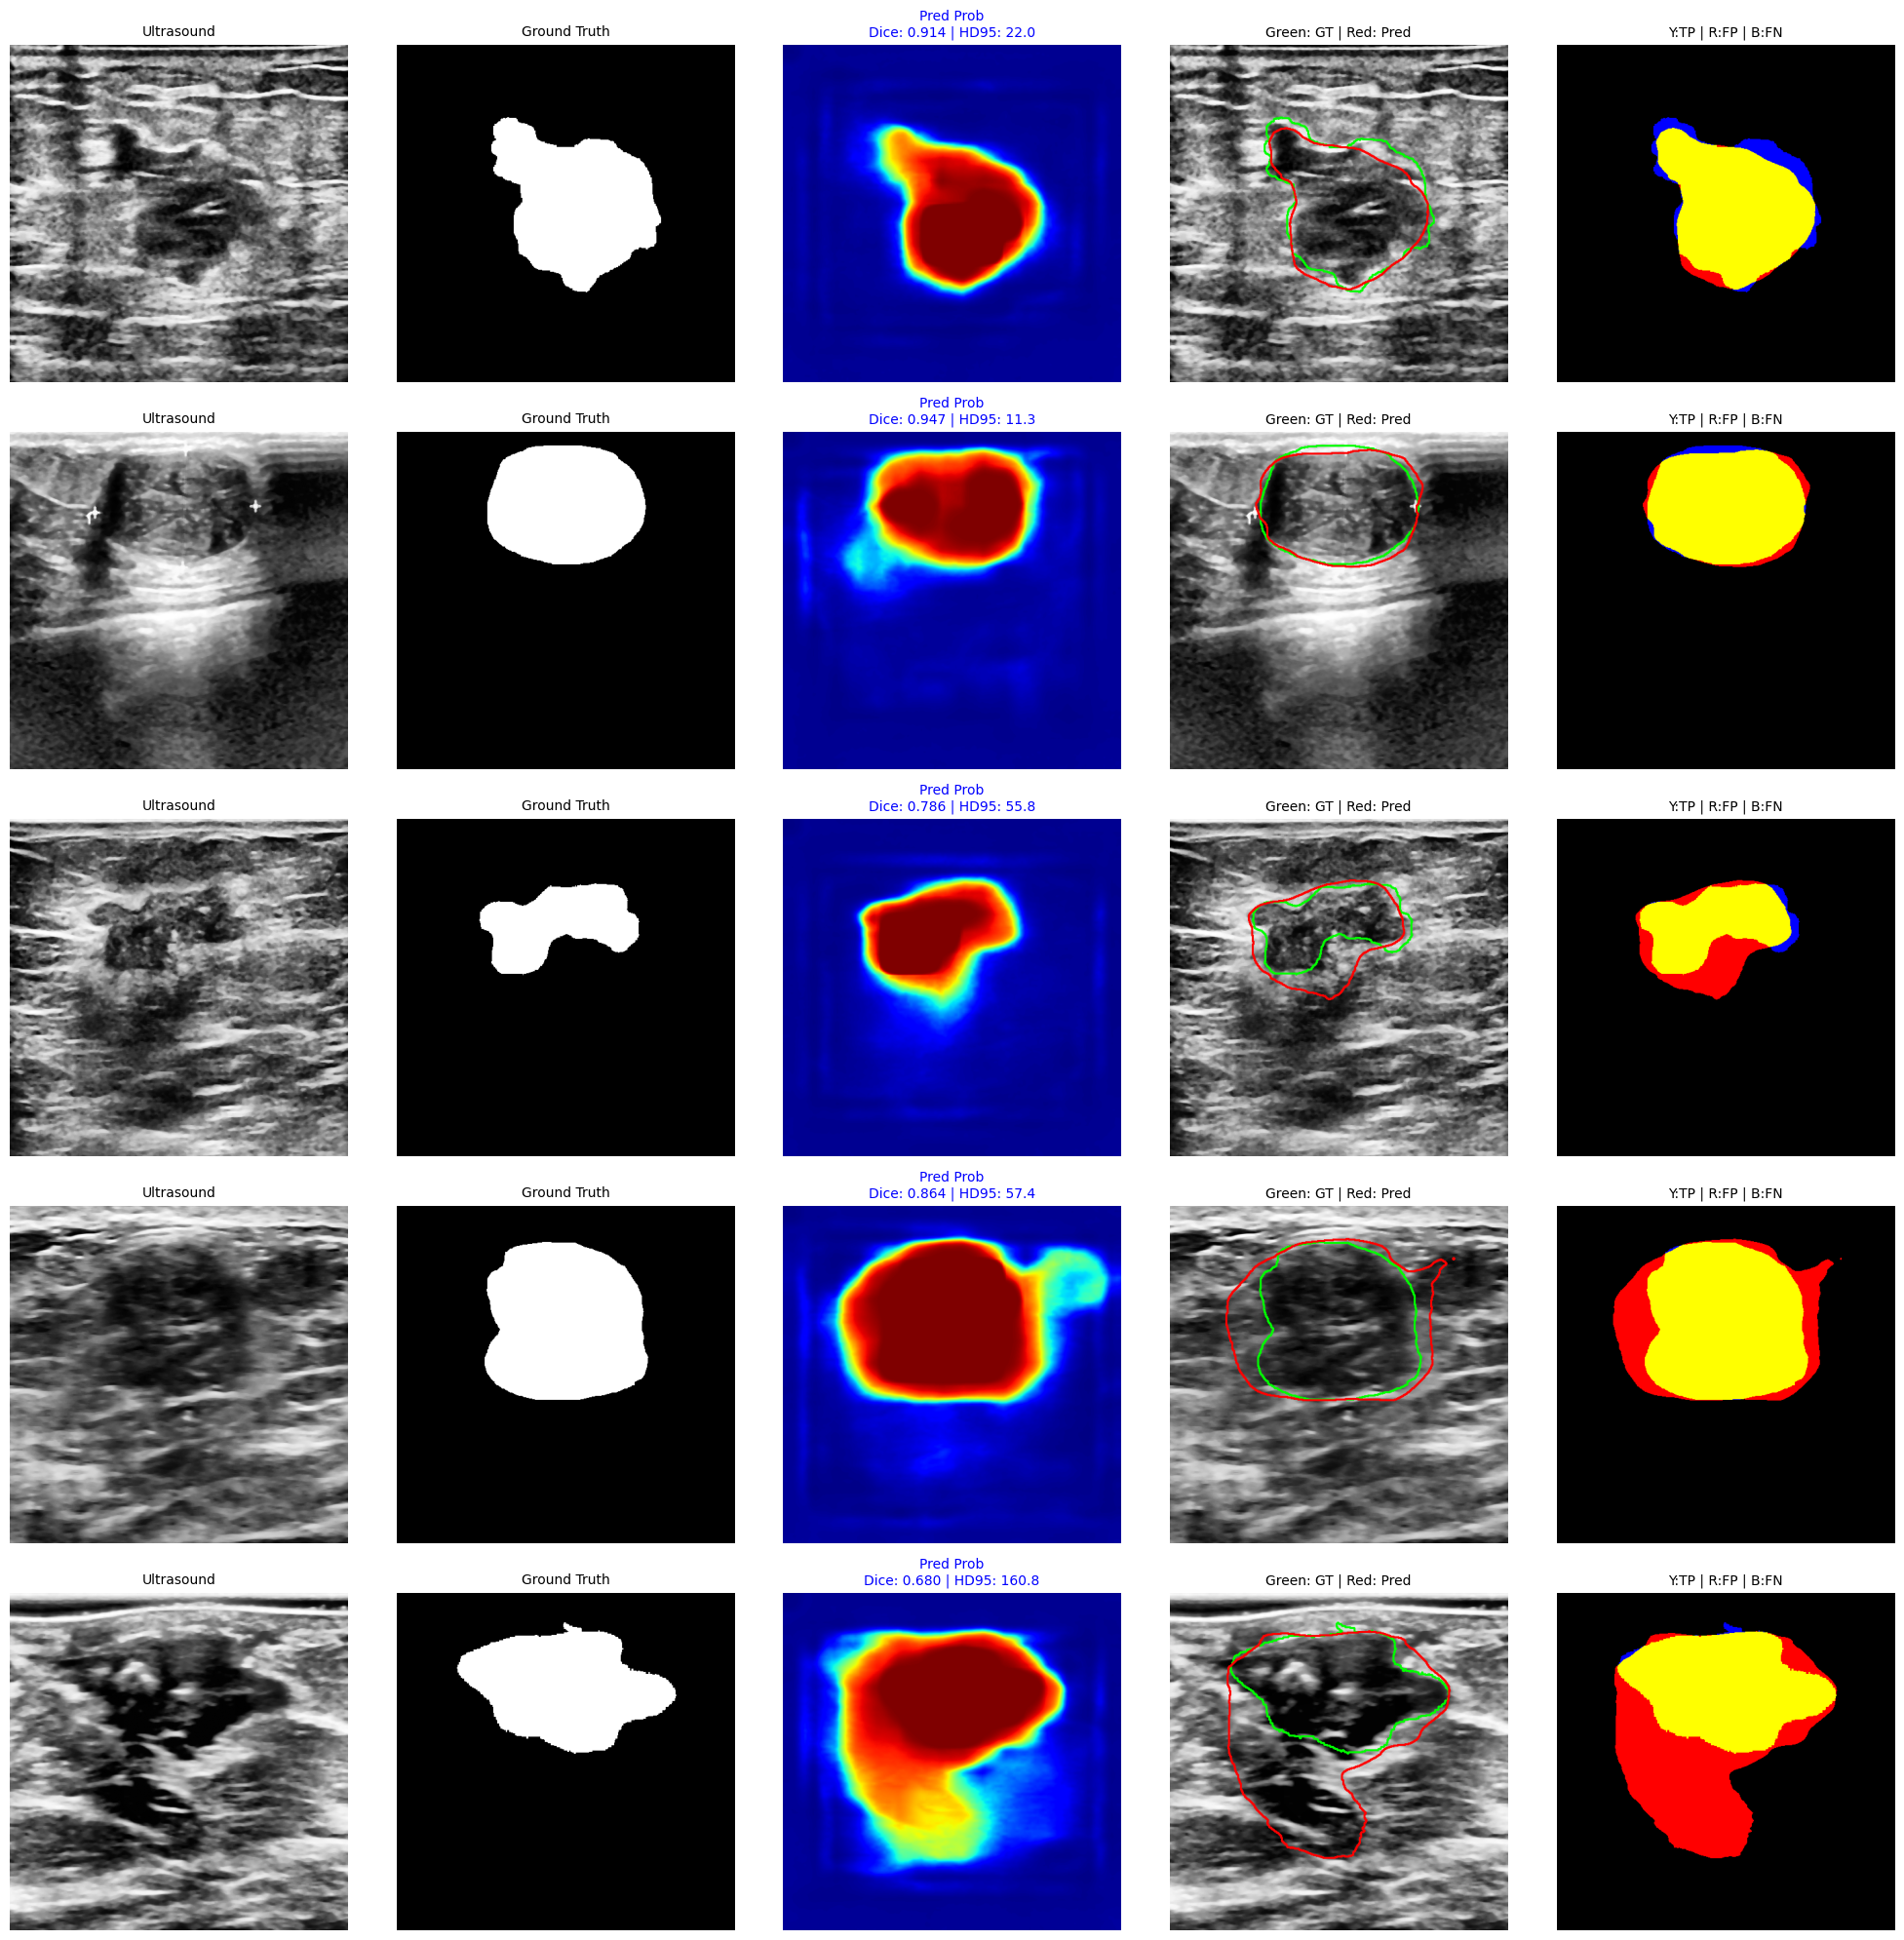

In [31]:
folds_generator = stratified_kfold_split(seg_patients, n_splits=n_splits)
_, val_patients_fold1 = next(folds_generator)

model_path_fold1 = os.path.join(exp_manager.weights_dir, "model_fold1.pt")
print(f"📂 Caricamento pesi da: {model_path_fold1}")

if os.path.exists(model_path_fold1):
    print(f"🖼️ Generazione grafici per il Fold 1...")
    visualize_rich_validation(
        model_path=model_path_fold1, 
        val_samples=val_patients_fold1,
        num_samples=5,
        device=device
    )
else:
    print("❌ Errore: File dei pesi non trovato. Il training è stato completato?")